In [1]:
import warnings
warnings.filterwarnings('ignore')

import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

from enigmatoolbox.plotting import plot_cortical, plot_subcortical
from enigmatoolbox.utils.parcellation import parcel_to_surface

import sys
sys.path.append('..')

from helper.func import general_linear_model

In [ ]:
project_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
results_dir = os.path.join(project_dir, '...')

In [ ]:
## Demographics
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'), index_col=0)
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## cortical thickness
ctx_tle = pd.read_csv(os.path.join(results_dir,  '...', 'ctx_tle.csv'), index_col=0)
ctx_ige = pd.read_csv(os.path.join(results_dir, '...', '...', 'ctx_ige.csv'), index_col=0)

## subcortical volume
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle.csv'), index_col=0)
sv_ige = pd.read_csv(os.path.join(results_dir, '...', 'sv_ige.csv'), index_col=0)

In [4]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl

my_rdbu = LinearSegmentedColormap.from_list(
    "my_rdbu", ["#174fa0", "#2f89c2", "#f7f7f7", "#df5948", "#ad0c28"], N=256)

try:
    mpl.colormaps.register(my_rdbu)
except ValueError:
    pass

## Effects of diagnosis in males

In [5]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

male_diagnosis = {}

for epi in ['tle', 'ige']:
    male_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv']:
        male_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"
        male_diagnosis[epi][biomarker] = glm.diagnosis_effects_across_sexes(
            df_name=df_name, group_col='Dx', age_col='Age',
            sex_col='Sex', icv_col='ICV', gender='male'
        )

2026-05-28 16:48:31,996 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 16:48:32,019 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 16:48:32,037 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 16:48:32,073 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical v

In [6]:
## reorganize the result
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

male_metrics = {}
for metric in metrics:
    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        male_metrics[key] = None

for metric in metrics:
    metric_key = f"{metric}_values" if metric != 'cohen' else 'cohen_d'
    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        stacked_values = []
        
        for epi in epi_types:
            stacked_values.append(male_diagnosis[epi][biomarker][metric_key])
        
        male_metrics[key] = np.vstack(stacked_values)

Cortical thickness in TLE

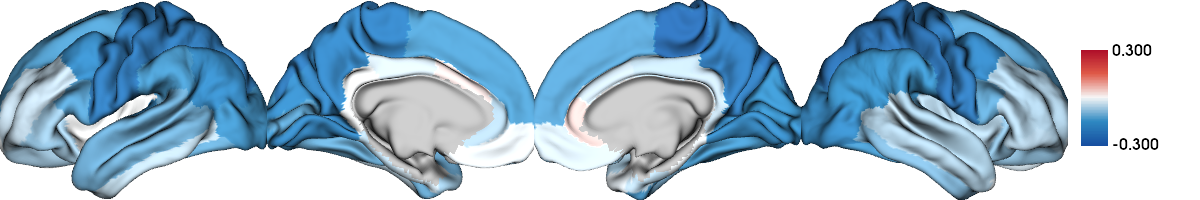

In [7]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(male_metrics['cohen_ctx'][0], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=True, color_range=(-0.3, 0.3))

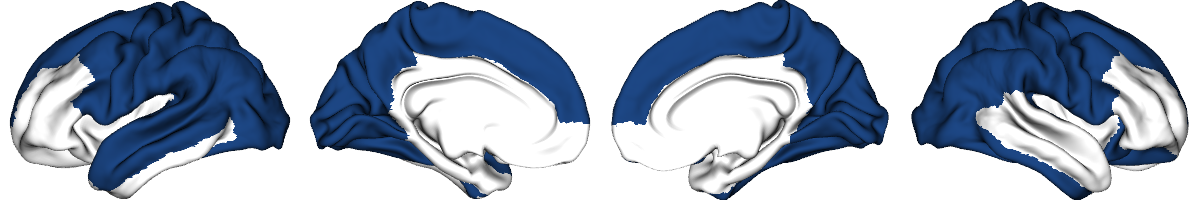

In [8]:
# plot p significant regions in TLE

p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [9]:
## Check which areas are significant
q_ctx_tle = pd.Series(male_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')

# brain areas where tle showed significance
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_cuneus', 'L_fusiform',
       'L_inferiorparietal', 'L_lateraloccipital', 'L_lingual',
       'L_middletemporal', 'L_paracentral', 'L_parsopercularis',
       'L_pericalcarine', 'L_postcentral', 'L_precentral', 'L_precuneus',
       'L_superiorfrontal', 'L_superiorparietal', 'L_superiortemporal',
       'L_supramarginal', 'L_transversetemporal', 'R_caudalmiddlefrontal',
       'R_cuneus', 'R_fusiform', 'R_inferiorparietal', 'R_inferiortemporal',
       'R_lateraloccipital', 'R_lateralorbitofrontal', 'R_lingual',
       'R_paracentral', 'R_parsopercularis', 'R_pericalcarine',
       'R_postcentral', 'R_precentral', 'R_precuneus', 'R_superiorfrontal',
       'R_superiorparietal', 'R_supramarginal', 'R_transversetemporal'],
      dtype='object')

In [10]:
len(q_ctx_tle[q_ctx_tle < 0.05])

37

In [11]:
# get the cohen's d values range for TLE in males
male_metrics['cohen_ctx'][0].min(), male_metrics['cohen_ctx'][0].max()

(-0.24250206564932172, 0.031298712627010984)

IGE

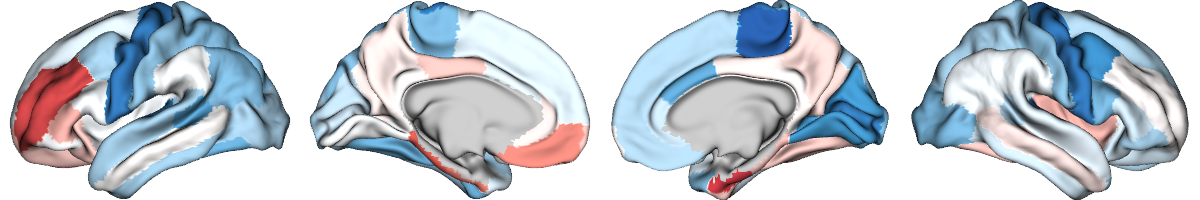

In [13]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(male_metrics['cohen_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

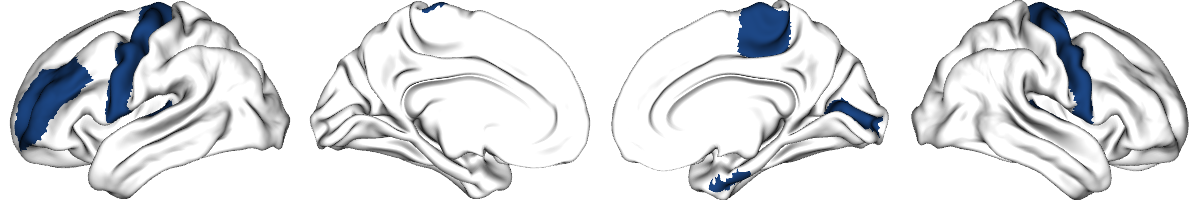

In [14]:
# plot p significant regions in IGE
p_ctx_surf = parcel_to_surface(male_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [15]:
## Check which areas are significant
q_ctx_ige = pd.Series(male_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05]

L_precentral              0.008959
L_rostralmiddlefrontal    0.015022
L_transversetemporal      0.025482
R_entorhinal              0.008959
R_paracentral             0.000570
R_pericalcarine           0.015022
R_precentral              0.008959
R_transversetemporal      0.008959
Name: pFDR, dtype: float64

In [16]:
# get the cohen's d values range for IGE in males
male_metrics['cohen_ctx'][1].min(), male_metrics['cohen_ctx'][1].max()

(-0.2999725343844693, 0.24296033733483124)

Subcortical volumes in TLE

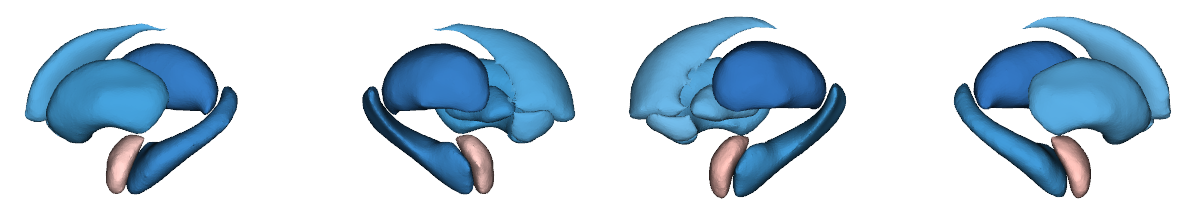

In [17]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['cohen_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))


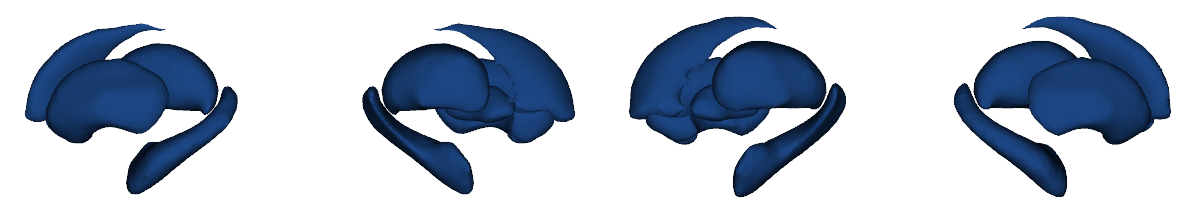

In [ ]:
# plot p significant regions in TLE
sig_mask = np.where(male_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [19]:
## Check which subcortical areas are significant in TLE
q_sv_tle = pd.Series(male_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')

q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal', 'Raccumb',
       'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [20]:
# get the cohen's d values range for TLE in males
male_metrics['cohen_sv'][0].min(), male_metrics['cohen_sv'][0].max()

(-0.2536921033414682, 0.06688952522502703)

IGE

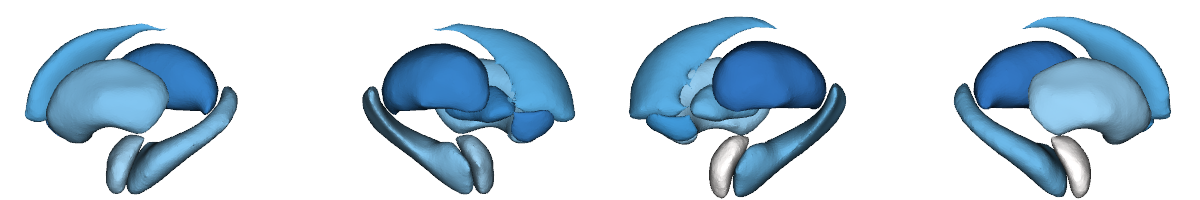

In [22]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(male_metrics['cohen_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

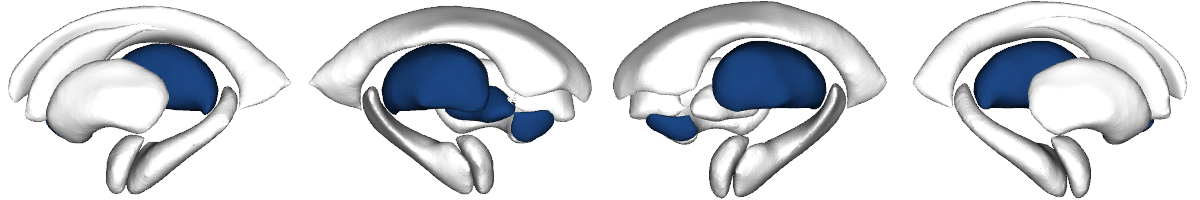

In [23]:
# plot p significant regions in IGE
sig_mask = np.where(male_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), ventricles=False, zoom=1.8, nan_color=(1, 1, 1, 1), interactive=False, embed_nb=True, 
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [24]:
## Check which subcortical areas are significant in IGE
q_sv_ige = pd.Series(male_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05]

Laccumb    0.003459
Lpal       0.007809
Lthal      0.003459
Raccumb    0.024329
Rthal      0.001752
Name: pFDR, dtype: float64

In [25]:
# get the cohen's d values range for IGE in males
male_metrics['cohen_sv'][1].min(), male_metrics['cohen_sv'][1].max()

(-0.25681653227816376, 0.002526226668901995)

## Effects of diagnosis in females

In [27]:
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

female_diagnosis = {}

for epi in ['tle', 'ige']:
    female_diagnosis[epi] = {}
    for biomarker in ['ctx', 'sv', 'sa']:
        female_diagnosis[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        female_diagnosis[epi][biomarker] = glm.diagnosis_effects_across_sexes(
            df_name=df_name, group_col='Dx', age_col='Age',
            sex_col='Sex', icv_col='ICV', gender='female'
        )

2026-05-27 18:37:18,106 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-27 18:37:18,131 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.


2026-05-27 18:37:18,151 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-27 18:37:18,182 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.


In [28]:
## reorganize the result
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

female_metrics = {}

for metric in metrics:
    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        female_metrics[key] = None

for metric in metrics:
    metric_key = f"{metric}_values" if metric != 'cohen' else 'cohen_d'

    for biomarker in biomarkers:
        key = f'{metric}_{biomarker}'
        stacked_values = []
        for epi in epi_types:
            stacked_values.append(female_diagnosis[epi][biomarker][metric_key])
            
        female_metrics[key] = np.vstack(stacked_values)

Cortical thickness in TLE

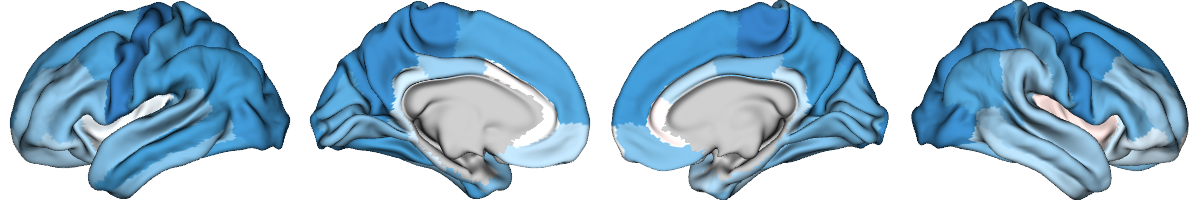

In [29]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(female_metrics['cohen_ctx'][0], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

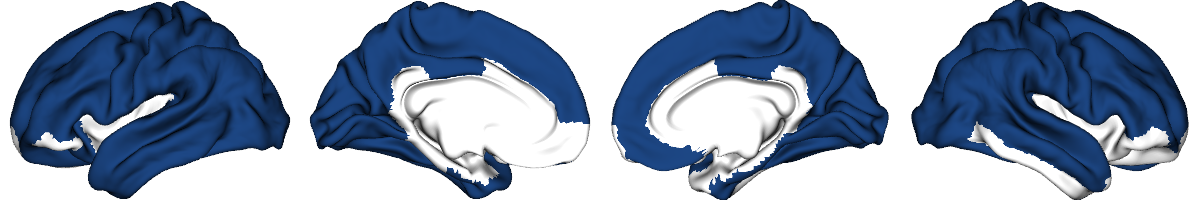

In [30]:
# plot p-sig areas in TLE
p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [31]:
## Check which areas are significant
q_ctx_tle = pd.Series(female_metrics['q_ctx'][0], index=ctx_tle.columns, name='pFDR')

# brain areas where tle showed significance
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_bankssts', 'L_caudalmiddlefrontal', 'L_cuneus', 'L_entorhinal',
       'L_fusiform', 'L_inferiorparietal', 'L_inferiortemporal',
       'L_lateraloccipital', 'L_lateralorbitofrontal', 'L_lingual',
       'L_middletemporal', 'L_paracentral', 'L_parsopercularis',
       'L_parstriangularis', 'L_pericalcarine', 'L_postcentral',
       'L_posteriorcingulate', 'L_precentral', 'L_precuneus',
       'L_rostralmiddlefrontal', 'L_superiorfrontal', 'L_superiorparietal',
       'L_superiortemporal', 'L_supramarginal', 'L_temporalpole',
       'L_transversetemporal', 'R_bankssts', 'R_caudalmiddlefrontal',
       'R_cuneus', 'R_entorhinal', 'R_fusiform', 'R_inferiorparietal',
       'R_lateraloccipital', 'R_lingual', 'R_medialorbitofrontal',
       'R_middletemporal', 'R_parahippocampal', 'R_paracentral',
       'R_parsopercularis', 'R_parstriangularis', 'R_pericalcarine',
       'R_postcentral', 'R_posteriorcingulate', 'R_precentral', 'R_precuneus',
       'R_rostralmiddlefrontal', 'R_su

In [32]:
len(q_ctx_tle[q_ctx_tle < 0.05])

51

In [33]:
# get the cohen's d values range for TLE in males
female_metrics['cohen_ctx'][0].min(), female_metrics['cohen_ctx'][0].max()

(-0.2230866908359524, 0.032644707855160444)

IGE

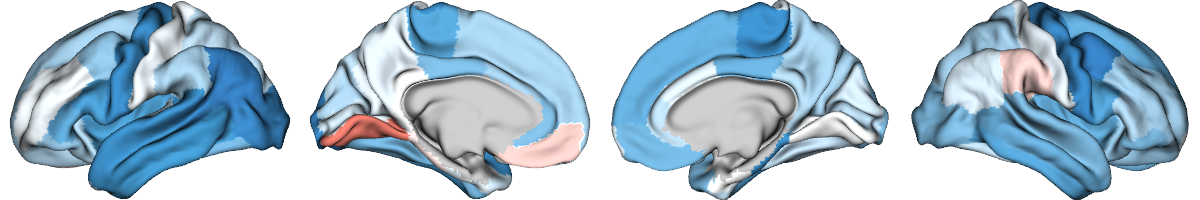

In [35]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

cohen_ctx_surf = parcel_to_surface(female_metrics['cohen_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

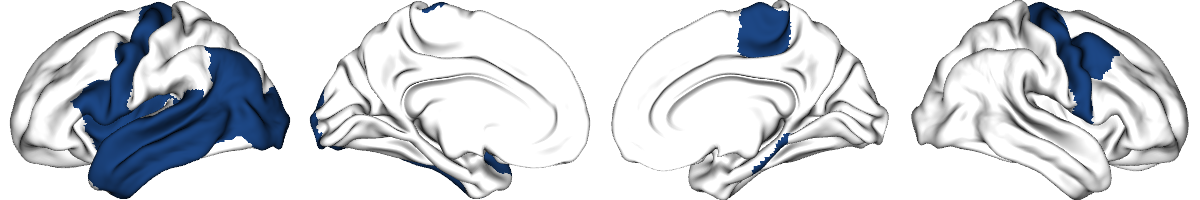

In [36]:
# plot p-sig areas in IGE

p_ctx_surf = parcel_to_surface(female_metrics['q_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [37]:
## Check which areas are significant
q_ctx_ige = pd.Series(female_metrics['q_ctx'][1], index=ctx_ige.columns, name='pFDR')

q_ctx_ige[q_ctx_ige < 0.05].index

Index(['L_bankssts', 'L_inferiorparietal', 'L_inferiortemporal',
       'L_lateraloccipital', 'L_middletemporal', 'L_parsopercularis',
       'L_precentral', 'L_superiortemporal', 'L_insula',
       'R_caudalmiddlefrontal', 'R_parahippocampal', 'R_paracentral',
       'R_precentral'],
      dtype='object')

In [38]:
len(q_ctx_ige[q_ctx_ige < 0.05])

13

In [39]:
# get the cohen's d values range for IGE in males
female_metrics['cohen_ctx'][1].min(), female_metrics['cohen_ctx'][1].max()

(-0.21645206742661888, 0.12960887681280533)

Subcortical volumes in TLE

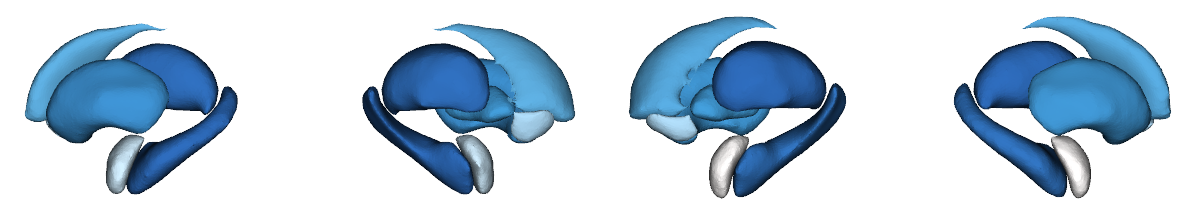

In [40]:
# plot cohen values in TLE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['cohen_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))


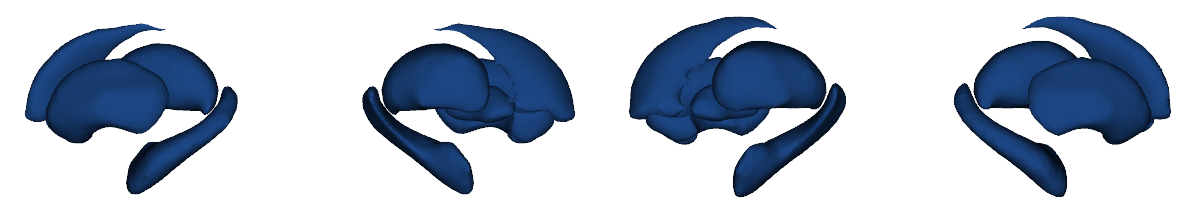

In [41]:
# plot p-sig areas in TLE

sig_mask = np.where(female_metrics['q_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [42]:
## Check which subcortical areas are significant in TLE
q_sv_tle = pd.Series(female_metrics['q_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal', 'Raccumb',
       'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [43]:
# get the cohen's d values range for TLE in males
female_metrics['cohen_sv'][0].min(), female_metrics['cohen_sv'][0].max()

(-0.2830863837097946, 0.0031912552995852854)

IGE

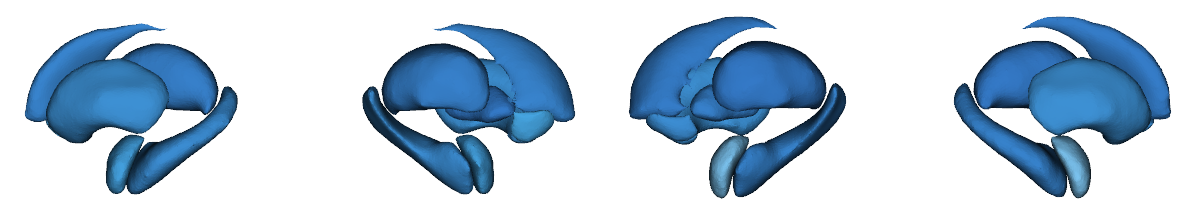

In [45]:
# plot cohen values in IGE
# label_text = ['TLE', 'IGE']

plot_subcortical(female_metrics['cohen_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                             label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

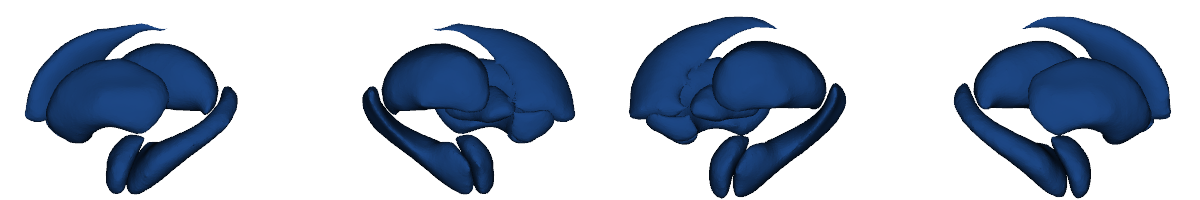

In [ ]:
# plot p-sig areas in IGE
sig_mask = np.where(female_metrics['q_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [47]:
## Check which subcortical areas are significant in IGE
q_sv_ige = pd.Series(female_metrics['q_sv'][1], index=sv_ige.columns, name='pFDR')
q_sv_ige[q_sv_ige < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [48]:
# get the cohen's d values range for IGE in males
female_metrics['cohen_sv'][1].min(), female_metrics['cohen_sv'][1].max()

(-0.25473324565858424, -0.11038891889181116)

## Effect of sex and diagnosis-sex interaction across cohorts

In [4]:
## glm comparison 
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

comparison_types = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

results = {}
for epi in ['tle', 'ige']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv', 'sa']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.biomarker_comparison(
                df_name=df_name, comparison_type=comparison_type, age_col='Age',
                sex_col='Sex', icv_col='ICV', group_col='Dx'
            )

2026-05-27 18:59:22,362 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.


2026-05-27 18:59:22,370 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-27 18:59:22,437 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-27 18:59:22,516 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-27 18:59:22,544 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variabl

In [ ]:
# reorganize the results
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

result_dicts = {}
for epi in epi_types:
    for metric in metrics:
        for biomarker in biomarkers:
            key = f"{metric}_{epi}_{biomarker}"
            result_dicts[key] = {}

for epi in epi_types:
    for biomarker in biomarkers:
        # t values
        t_values = np.vstack([
            results[epi][biomarker]['case_control']['t_values'],
            results[epi][biomarker]['sex_in_epi']['t_values'],
            results[epi][biomarker]['sex_in_hc']['t_values'],
            results[epi][biomarker]['sex_group_interaction']['t_values']
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values
        
        # q values
        q_values = np.vstack([
            results[epi][biomarker]['case_control']['q_values'],
            results[epi][biomarker]['sex_in_epi']['q_values'],
            results[epi][biomarker]['sex_in_hc']['q_values'],
            results[epi][biomarker]['sex_group_interaction']['q_values']
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values
        
        # cohen's d
        cohen_values = np.vstack([
            results[epi][biomarker]['case_control']['cohen_d'],
            results[epi][biomarker]['sex_in_epi']['cohen_d'],
            results[epi][biomarker]['sex_in_hc']['cohen_d'],
            results[epi][biomarker]['sex_group_interaction']['cohen_d']
        ])
        
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values

Sex effects in cortical thickness in TLE

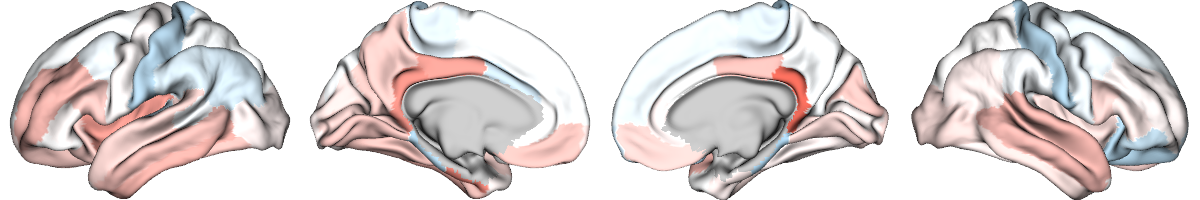

In [9]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

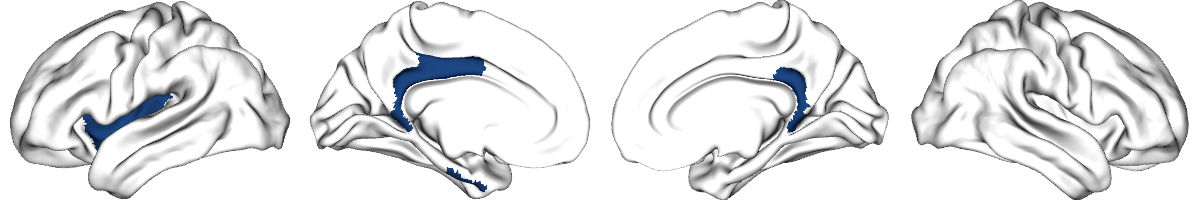

In [10]:
# plot p-sig areas in TLE
# label_text = ['TLE', 'IGE']

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [11]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][1], index=ctx_tle.columns, name='pFDR')

# brain areas where tle showed significance
q_ctx_tle[q_ctx_tle < 0.05].index

Index(['L_entorhinal', 'L_isthmuscingulate', 'L_posteriorcingulate',
       'L_insula', 'R_isthmuscingulate'],
      dtype='object')

In [12]:
len(q_ctx_tle[q_ctx_tle < 0.05])

5

In [13]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_ctx'][1].min(), result_dicts['cohen_tle_ctx'][1].max()

(-0.06749211308759419, 0.14843967035418026)

Sex effects in healthy control

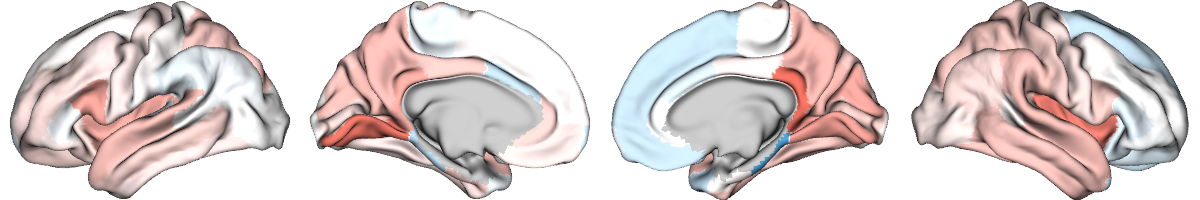

In [14]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][2], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

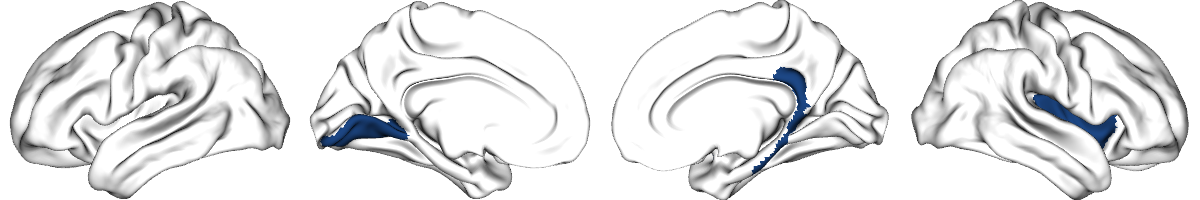

In [15]:
# plot p-sig areas in TLE

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][2], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [16]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

## Check which areas are significant in epilepsy
q_ctx_hc = pd.Series(result_dicts['q_tle_ctx'][2], index=ctx_tle.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index(['L_lingual', 'R_isthmuscingulate', 'R_parahippocampal', 'R_insula'], dtype='object')

In [17]:
len(q_ctx_hc[q_ctx_hc < 0.05])

4

In [18]:
# get the cohen's d values range for sex in healthy control
result_dicts['cohen_tle_ctx'][2].min(), result_dicts['cohen_tle_ctx'][2].max()

(-0.13924371782213843, 0.14324849785359905)

Sex effects in interaction

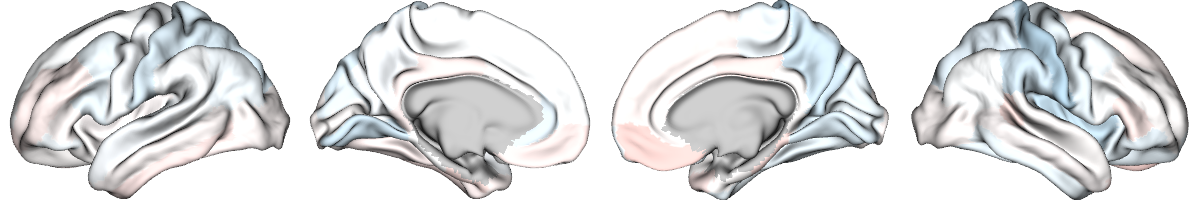

In [19]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

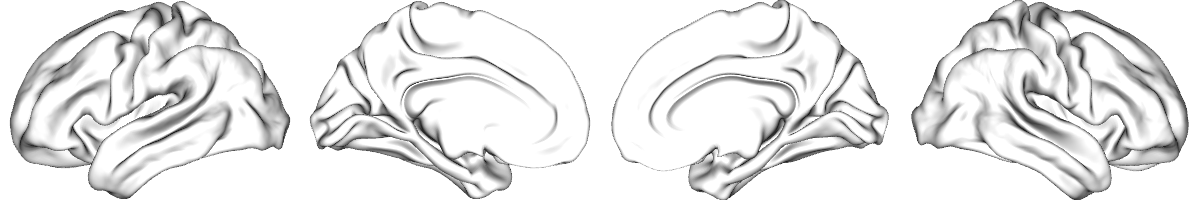

In [20]:
# plot p-sig areas in TLE
p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [21]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

## Check which areas are significant in epilepsy
q_ctx_hc = pd.Series(result_dicts['q_tle_ctx'][3], index=ctx_tle.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index([], dtype='object')

In [22]:
len(q_ctx_hc[q_ctx_hc < 0.05])

0

In [23]:
# get the cohen's d values range for sex in healthy control
result_dicts['cohen_tle_ctx'][3].min(), result_dicts['cohen_tle_ctx'][3].max()

(-0.051577814546118865, 0.040843238277363705)

Subcortical volume

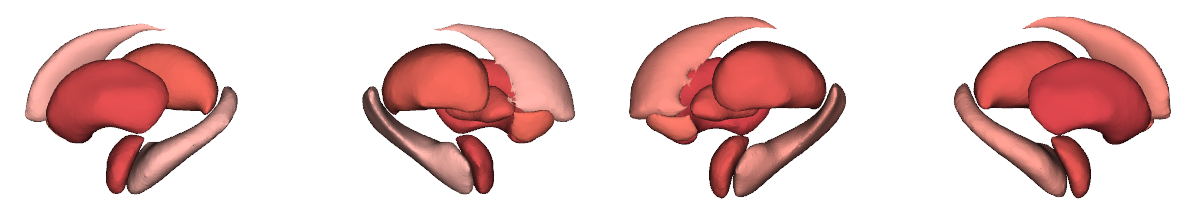

In [24]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))


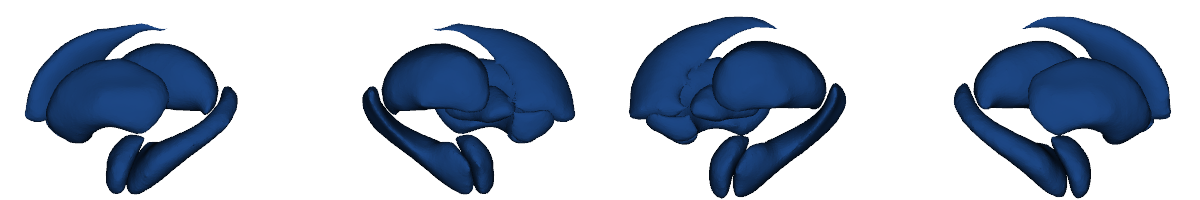

In [25]:
# plot p-sig areas in TLE

sig_mask = np.where(result_dicts['q_tle_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [26]:
## Check which areas are significant in epilepsy
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][1], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [27]:
len(q_sv_tle[q_sv_tle < 0.05])

14

In [28]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][1].min(), result_dicts['cohen_tle_sv'][1].max()

(0.08097133526679941, 0.22882522682236467)

Sex effects in healthy control

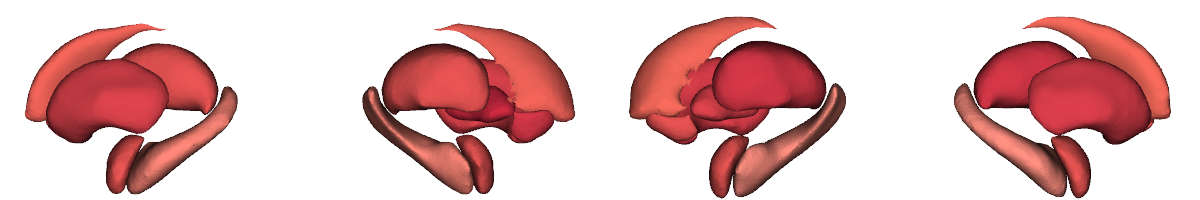

In [29]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_sv'][2], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

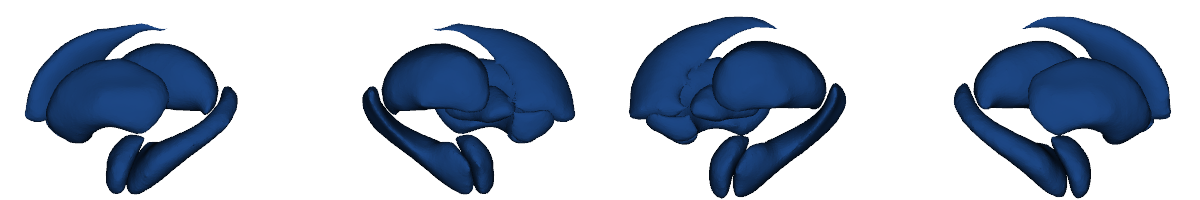

In [30]:
# plot p-sig areas in TLE
sig_mask = np.where(result_dicts['q_tle_sv'][2] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [31]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

## Check which areas are significant in epilepsy
q_sv_hc = pd.Series(result_dicts['q_tle_sv'][2], index=sv_tle.columns, name='pFDR')
q_sv_hc[q_sv_hc < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lcaud', 'Lhippo', 'Lpal', 'Lput', 'Lthal',
       'Raccumb', 'Ramyg', 'Rcaud', 'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [32]:
len(q_sv_hc[q_sv_hc < 0.05])

14

In [33]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][2].min(), result_dicts['cohen_tle_sv'][2].max()

(0.12098494617491329, 0.2796487486330201)

Sex diagnosis interaction effects

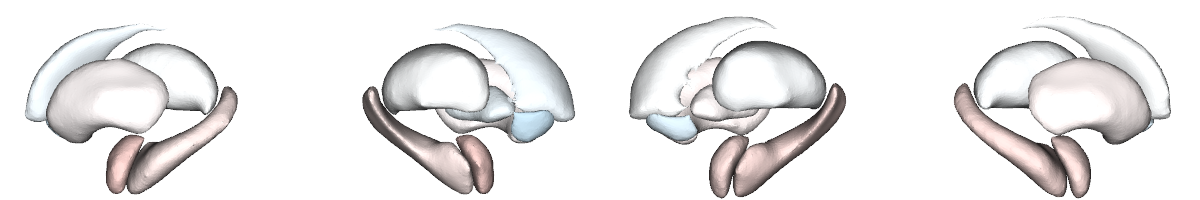

In [34]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

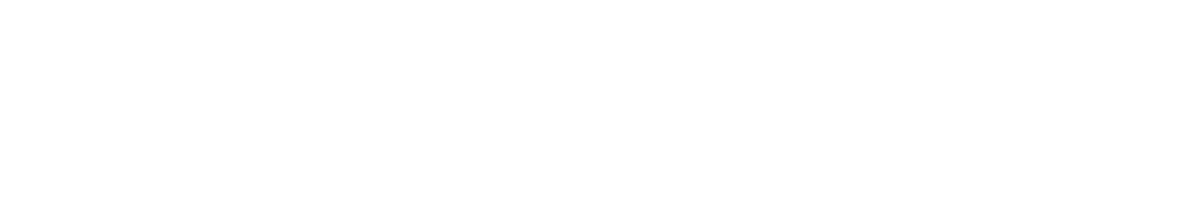

In [35]:
# plot p-sig areas in TLE

sig_mask = np.where(result_dicts['q_tle_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [36]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

## Check which areas are significant in epilepsy
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][3], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object')

In [37]:
len(q_sv_tle[q_sv_tle < 0.05])

0

In [38]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][3].min(), result_dicts['cohen_tle_sv'][3].max()

(-0.04557878994988027, 0.045493891772233834)

Sex effects in cortical thickness in IGE

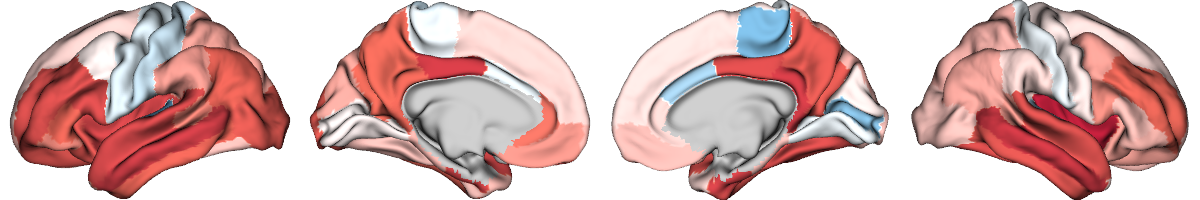

In [39]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_ige_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

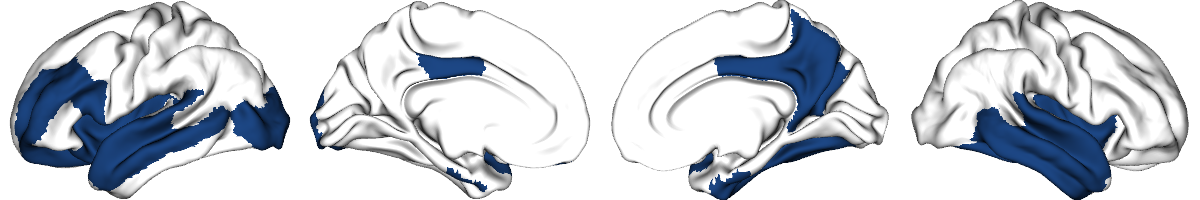

In [40]:
# plot p-sig areas in TLE

p_ctx_surf = parcel_to_surface(result_dicts['q_ige_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [41]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

## Check which areas are significant in epilepsy
q_ctx_ige = pd.Series(result_dicts['q_ige_ctx'][1], index=ctx_ige.columns, name='pFDR')
q_ctx_ige[q_ctx_ige < 0.05].index

Index(['L_entorhinal', 'L_lateraloccipital', 'L_lateralorbitofrontal',
       'L_middletemporal', 'L_parsopercularis', 'L_posteriorcingulate',
       'L_rostralmiddlefrontal', 'L_superiortemporal', 'L_insula',
       'R_entorhinal', 'R_fusiform', 'R_inferiortemporal',
       'R_isthmuscingulate', 'R_middletemporal', 'R_posteriorcingulate',
       'R_precuneus', 'R_superiortemporal', 'R_insula'],
      dtype='object')

In [42]:
len(q_ctx_ige[q_ctx_ige < 0.05])

18

In [43]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_ctx'][1].min(), result_dicts['cohen_ige_ctx'][1].max()

(-0.11544753937381347, 0.3340395276679753)

Sex effects in healthy control

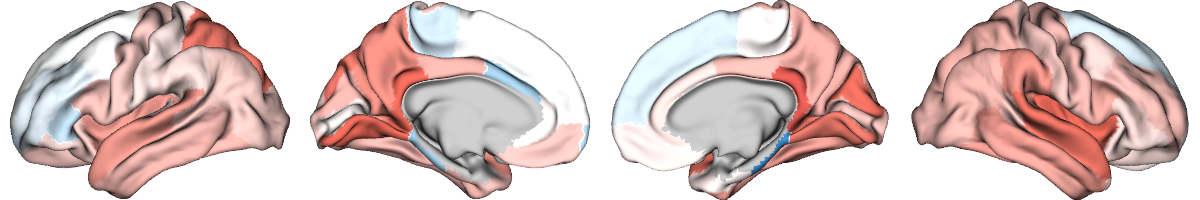

In [45]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_ige_ctx'][2], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

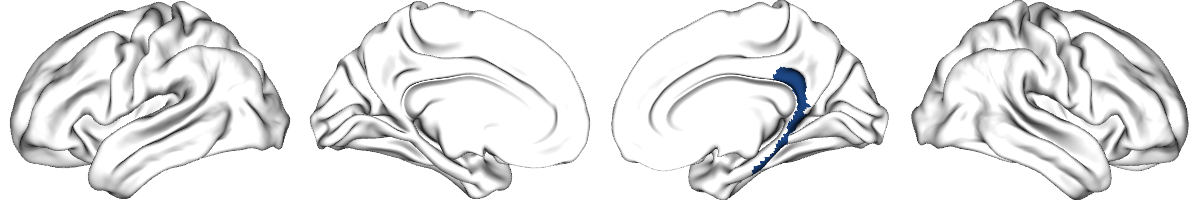

In [46]:
# plot p-sig areas in TLE

p_ctx_surf = parcel_to_surface(result_dicts['q_ige_ctx'][2], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [47]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

## Check which areas are significant in epilepsy
q_ctx_hc = pd.Series(result_dicts['q_ige_ctx'][2], index=ctx_ige.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index(['R_isthmuscingulate', 'R_parahippocampal'], dtype='object')

In [48]:
len(q_ctx_hc[q_ctx_hc < 0.05])

2

In [49]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_ctx'][2].min(), result_dicts['cohen_ige_ctx'][2].max()

(-0.18028662119682015, 0.17685569168594156)

Sex effects in interaction

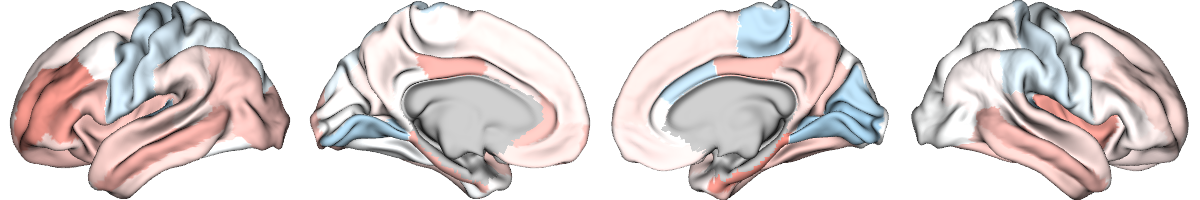

In [51]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_ige_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

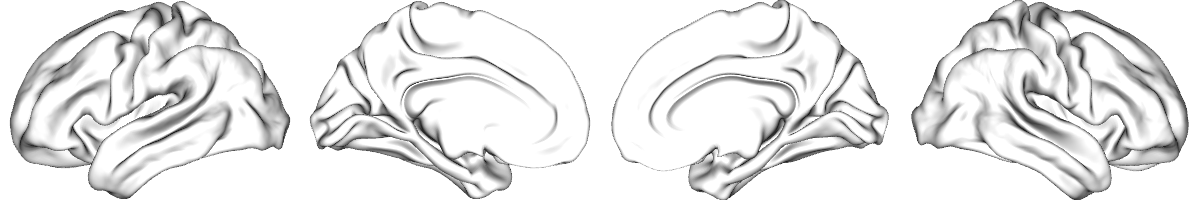

In [52]:
# plot p-sig areas in TLE
p_ctx_surf = parcel_to_surface(result_dicts['q_ige_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [53]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

## Check which areas are significant in epilepsy
q_ctx_hc = pd.Series(result_dicts['q_ige_ctx'][3], index=ctx_ige.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index([], dtype='object')

In [54]:
len(q_ctx_hc[q_ctx_hc < 0.05])

0

In [55]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_ctx'][3].min(), result_dicts['cohen_ige_ctx'][3].max()

(-0.07419076361732924, 0.11450401567746225)

Subcortical volume

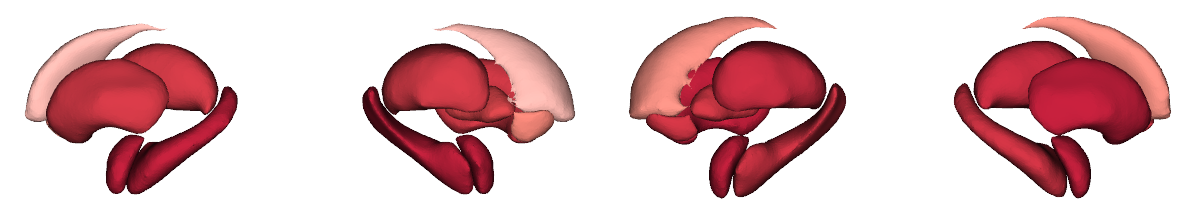

In [57]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_ige_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

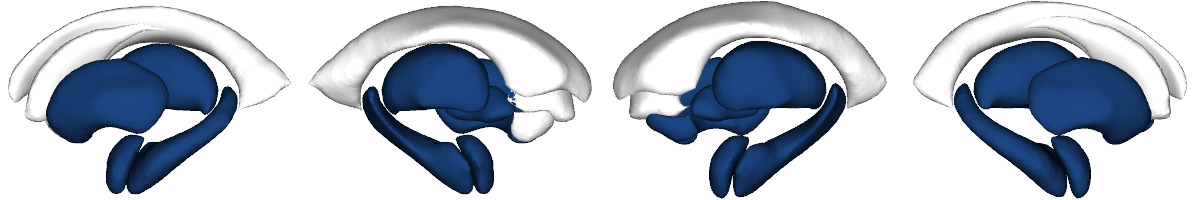

In [58]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_ige_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [59]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

## Check which areas are significant in epilepsy
q_sv_ige = pd.Series(result_dicts['q_ige_sv'][1], index=sv_ige.columns, name='pFDR')

# brain areas where tle showed significance
q_sv_ige[q_sv_ige < 0.05].index

Index(['Lamyg', 'Lhippo', 'Lpal', 'Lput', 'Lthal', 'Raccumb', 'Ramyg',
       'Rhippo', 'Rpal', 'Rput', 'Rthal'],
      dtype='object')

In [60]:
len(q_sv_ige[q_sv_ige < 0.05])

11

In [61]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_sv'][1].min(), result_dicts['cohen_ige_sv'][1].max()

(0.07462707082008554, 0.38458645518398854)

Sex effects in healthy control

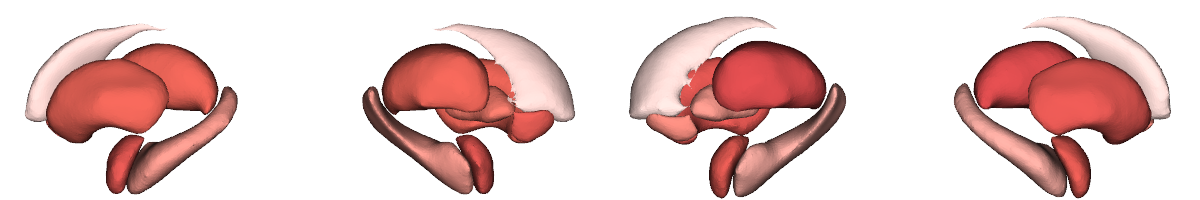

In [63]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_ige_sv'][2], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))


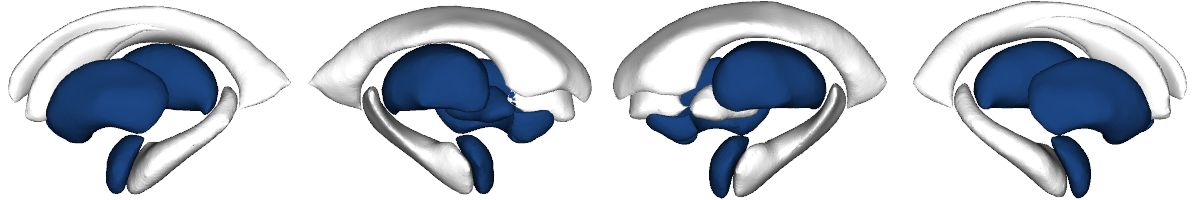

In [64]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_ige_sv'][2] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [65]:
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

## Check which areas are significant in epilepsy
q_sv_hc = pd.Series(result_dicts['q_ige_sv'][2], index=sv_ige.columns, name='pFDR')
q_sv_hc[q_sv_hc < 0.05].index

Index(['Laccumb', 'Lamyg', 'Lpal', 'Lput', 'Lthal', 'Raccumb', 'Ramyg', 'Rput',
       'Rthal'],
      dtype='object')

In [66]:
len(q_sv_hc[q_sv_hc < 0.05])

9

In [67]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_sv'][2].min(), result_dicts['cohen_ige_sv'][2].max()

(0.03844416039976203, 0.2096391313400808)

Sex diagnosis interaction effects

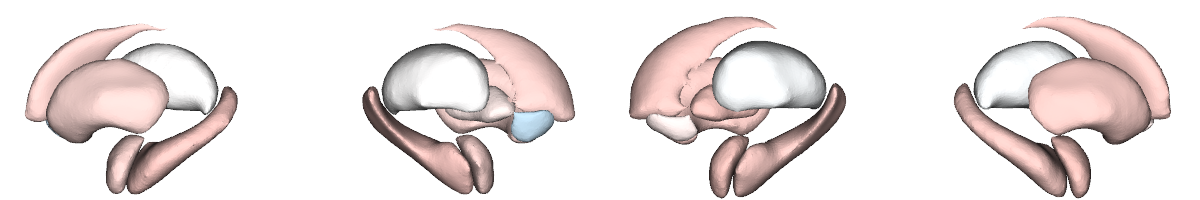

In [ ]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_ige_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

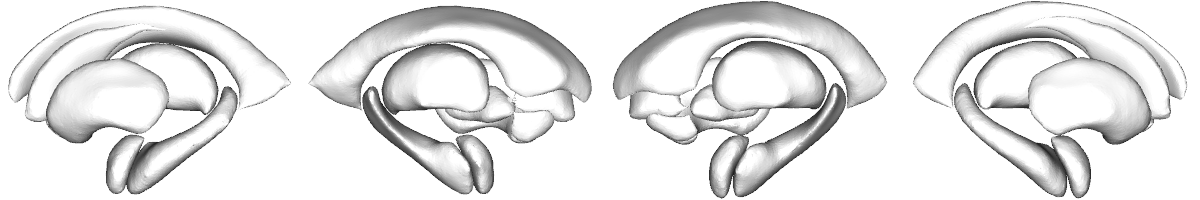

In [70]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_ige_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [71]:
## Check which areas are significant in epilepsy
q_sv_hc = pd.Series(result_dicts['q_ige_sv'][3], index=sv_ige.columns, name='pFDR')
q_sv_hc[q_sv_hc < 0.05].index

Index([], dtype='object')

In [72]:
len(q_sv_hc[q_sv_hc < 0.05])

0

In [73]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_ige_sv'][3].min(), result_dicts['cohen_ige_sv'][3].max()

(-0.05009000820246855, 0.05852985816209547)